<a href="https://colab.research.google.com/github/lewinskie254/timeseries-youtube/blob/main/Lecture_6_Timeseries_Analysis_ARIMA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from statsmodels.tsa.stattools import adfuller
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/marcopeix/TimeSeriesForecastingInPython/master/data/jj.csv")

<Axes: >

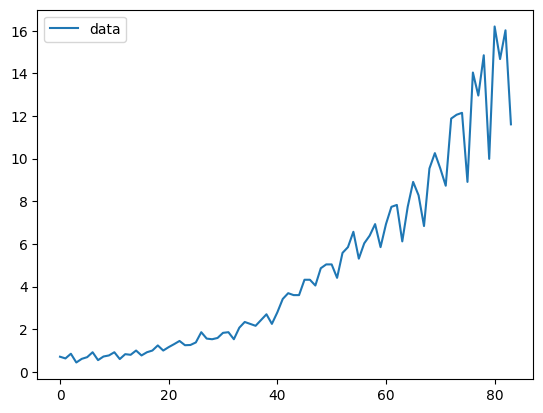

In [3]:
df.plot()

In [4]:
results = adfuller(df['data'])
print('ADF Statistic: %f' % results[0])
print('p-value: %f' % results[1])

ADF Statistic: 2.742017
p-value: 1.000000


/tmp/ipykernel_1395/3578501549.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  results = adfuller(df['data'])


In [5]:
df_diff = df['data'].diff()

In [6]:
results = adfuller(df_diff[1:])
print('ADF Statistic: %f' % results[0])
print('p-value: %f' % results[1])

ADF Statistic: -0.407410
p-value: 0.908854


/tmp/ipykernel_1395/859405103.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  results = adfuller(df_diff[1:])


<Axes: >

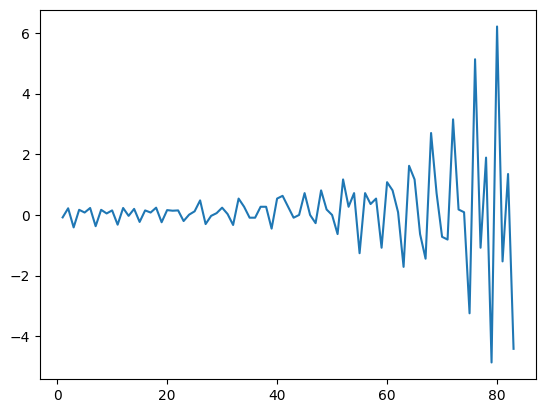

In [7]:
df_diff.plot()

In [8]:
df_diff_2 = df_diff.diff()

In [9]:
results = adfuller(df_diff_2[2:])
print('ADF Statistic: %f' % results[0])
print('p-value: %f' % results[1])

ADF Statistic: -3.585163
p-value: 0.006051


/tmp/ipykernel_1395/88161955.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  results = adfuller(df_diff_2[2:])


In [10]:
from itertools import product

#set the values of ps as a list of 0 to 5 with a step size of 1
ps = range(0, 5, 1)
#set the values of qs as a list of 0 to 5 with a step size of 1
qs = range(0, 5, 1)

d = [2]

#create a list of all possible combinations of Ps and Qs
order_list = list(product(ps, d, qs))

In [14]:
from typing import Union
from tqdm import tqdm_notebook
from statsmodels.tsa.statespace.sarimax import SARIMAX

# we pass several parameters: the endog (endogenous variables) which can either be a list or a pandas series, and an order list which is a list of tuples.
def optimize_ARIMA(endog: Union[pd.Series, list], order_list: list) -> pd.DataFrame:
  #this is a dataframe for storing the model's AIC scores
  results = []
  #we are using tqdm so that we can see the progress in the training as we loop through all combinations
  for order in tqdm_notebook(order_list):
    try:
      #use the sarimax model, indexing into the values of p and q from the orderlist tuples.
      model = SARIMAX(endog, order=(order[0], order[1], order[2])).fit(disp=False)
    except:
      #if there is no fit, instead of causing an error, just continue
      continue

    #get the AIC score from the SARIMAX inbuilt AIC property
    aic = model.aic

    #append the results to the results list
    results.append([order, aic])

  #create a dataframe of the rests for easier organization.
  result_df = pd.DataFrame(results)
  #add the column names for the rests
  result_df.columns = ['(p, d, q)', 'AIC']
  #Sort in ascending order, lower AIC is better
  result_df = result_df.sort_values(by='AIC', ascending=True).reset_index(drop=True)
  return result_df

In [15]:
best_models = optimize_ARIMA(df['data'], order_list)

/tmp/ipykernel_1395/3899156755.py:10: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for order in tqdm_notebook(order_list):


  0%|          | 0/25 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters foun

In [16]:
best_models.head(10)

,"(p, d, q)",AIC
0,"(3, 2, 4)",116.691377
1,"(3, 2, 3)",117.898281
2,"(4, 2, 1)",118.218067
3,"(4, 2, 4)",118.792776
4,"(4, 2, 0)",119.205133
5,"(3, 2, 1)",119.338719
6,"(3, 2, 2)",119.504218
7,"(4, 2, 2)",122.270879
8,"(4, 2, 3)",123.490288
9,"(3, 2, 0)",160.819666


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


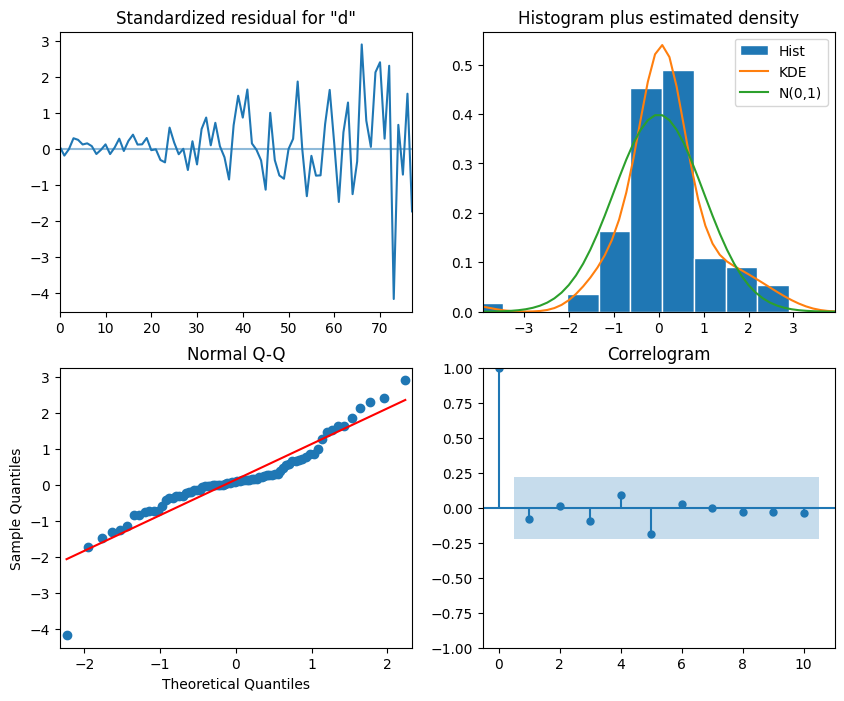

In [17]:
#testing out the model
train = df.data[:-4]


model = SARIMAX(train, order=(3,2,4), simple_differencing=False)
model_fit = model.fit(disp=False)
model_fit.plot_diagnostics(figsize=(10,8));

In [27]:
from statsmodels.stats.diagnostic import acorr_ljungbox
import numpy as np
residuals = model_fit.resid
acorr_ljungbox(residuals, np.arange(1, 11, 1))

,lb_stat,lb_pvalue
1,1.052667,0.304894
2,1.155829,0.561067
3,2.096980,0.552524
4,2.618396,0.623568
5,5.227757,0.388722
6,5.300901,0.505839
7,5.300967,0.623287
8,5.365893,0.717848
9,5.437967,0.794582
10,5.537337,0.852523


In [25]:
lbvalue

'lb_stat'

In [29]:
test = df.iloc[-4:]
test['naive_seasonal'] = df['data'].iloc[76:80].values
ARIMA_pred = model_fit.get_prediction(80, 83).predicted_mean
test['ARIMA_pred'] = ARIMA_pred

/tmp/ipykernel_1395/1139700339.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test['naive_seasonal'] = df['data'].iloc[76:80].values
/tmp/ipykernel_1395/1139700339.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test['ARIMA_pred'] = ARIMA_pred


In [30]:
test

,date,data,naive_seasonal,ARIMA_pred
80,1980-01-01,16.20,14.04,15.861609
81,1980-04-01,14.67,12.96,14.265104
82,1980-07-02,16.02,14.85,16.507020
83,1980-10-01,11.61,9.99,11.741607
